In [2]:
# Imports and environment first, all in one place

from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient

import os
os.environ["PATH"] = "/Users/miguelbayanspares/.nvm/versions/node/v22.11.0/bin:" + os.environ["PATH"]

load_dotenv(override=True)

True

# Agent Creation

In [3]:
agent = create_agent(
    model="openai:gpt-5.4-mini",
    system_prompt="You are a helpful assistant who answers concisely.",
)

result = agent.invoke({"messages": [{"role": "user", "content": "What is the Model Context Protocol, in two sentences?"}]})
print(result["messages"][-1].content)

The Model Context Protocol (MCP) is an open standard for connecting AI applications to external data sources and tools in a consistent way. It lets models securely discover and use context, such as files, databases, or APIs, without custom integrations for each one.


## Async call : ainvoke

In [4]:
result = await agent.ainvoke({"messages": [{"role": "user", "content": "In one sentence: why does async code suit agents so well?"}]})
print(result["messages"][-1].content)

Async code suits agents well because agents spend much of their time waiting on I/O, tools, and external systems, so asynchronous execution lets them stay responsive and handle multiple tasks concurrently instead of blocking.


In [5]:
@tool
def get_weather(city: str) -> str:
    """Return today's weather for a city."""
    pretend = {"London": "rainy, 14 degrees", "Rome": "sunny, 27 degrees"}
    return pretend.get(city, "clear, 20 degrees")

@tool
def get_population(city: str) -> str:
    """Return the population of a city."""
    pretend = {"London": "8.9 million", "Rome": "2.8 million"}
    return pretend.get(city, "unknown")

agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=[get_weather, get_population],
    system_prompt="You are a travel assistant. Use your tools to answer questions about cities.",
)

result = agent.invoke({"messages": [{"role": "user", "content": "What is the weather and population of Rome?"}]})
print(result["messages"][-1].content)

Rome is sunny, 27 degrees, and has a population of about 2.8 million.


# It creates the LangGraph for you

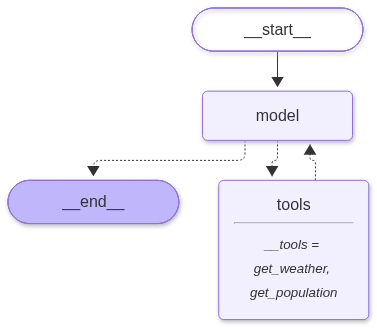

In [6]:
display(Image(agent.get_graph().draw_mermaid_png()))

# Memory

In [7]:
memory_agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=[get_weather],
    checkpointer=MemorySaver(),
    system_prompt="You are a travel assistant. Use your tools to answer questions about cities.",
)

config = {"configurable": {"thread_id": "trip-planning"}}
memory_agent.invoke({"messages": [{"role": "user", "content": "I am planning a trip to London."}]}, config=config)
result = memory_agent.invoke({"messages": [{"role": "user", "content": "What is the weather like where I am going on my trip?"}]}, config=config)
print(result["messages"][-1].content)

London is rainy and 14°C today. Bring a light waterproof jacket or umbrella.


# Structured Outputs

In [8]:
class CityReport(BaseModel):
    city: str = Field(description="The city name")
    weather: str = Field(description="A short weather description")
    population: str = Field(description="The population")

report_agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=[get_weather, get_population],
    response_format=CityReport,
)

result = report_agent.invoke({"messages": [{"role": "user", "content": "Give me a report on London."}]})
report = result["structured_response"]
print(report)
print("Just the weather:", report.weather)

city='London' weather='rainy, 14 degrees' population='8.9 million'
Just the weather: rainy, 14 degrees


# Middleware

Middleware is a powerful feature to shape an agent's behavior. It lets you run your own code at fixed points in the loop: before the model is called, after it answers, or around each tool call.

Here is a small piece of custom middleware that prints every tool call as it happens, so you can watch the agent at work. The @wrap_tool_call decorator wraps each tool call: we log it, then call handler to let it proceed.

In [9]:
@wrap_tool_call
def log_tool_calls(request, handler):
    call = request.tool_call
    print(f"  [middleware] calling {call['name']} with {call['args']}")
    return handler(request)

watched_agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=[get_weather, get_population],
    system_prompt="You are a travel assistant. Use your tools.",
    middleware=[log_tool_calls],
)

result = watched_agent.invoke({"messages": [{"role": "user", "content": "Weather and population of London and Rome?"}]})
print("\nFinal answer:", result["messages"][-1].content)

  [middleware] calling get_weather with {'city': 'Rome'}
  [middleware] calling get_population with {'city': 'London'}
  [middleware] calling get_population with {'city': 'Rome'}
  [middleware] calling get_weather with {'city': 'London'}

Final answer: Here’s the info for both cities:

- London: rainy, 14 degrees; population 8.9 million
- Rome: sunny, 27 degrees; population 2.8 million


In [10]:
!node --version
!npx --version

v26.13.0
11.20.0


In [11]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Not Windows, so nothing to do here


In [12]:
client = MultiServerMCPClient({
    "playwright": {
        "transport": "stdio",
        "command": "npx",
        "args": ["-y", "@playwright/mcp@latest", "--isolated"],
    }
})

browser_tools = await client.get_tools()
print(f"Loaded {len(browser_tools)} browser tools:")
for t in browser_tools:
    print(" -", t.name)

Loaded 25 browser tools:
 - browser_close
 - browser_resize
 - browser_console_messages
 - browser_handle_dialog
 - browser_emulate_media
 - browser_evaluate
 - browser_file_upload
 - browser_drop
 - browser_find
 - browser_fill_form
 - browser_press_key
 - browser_type
 - browser_navigate
 - browser_navigate_back
 - browser_network_requests
 - browser_network_request
 - browser_run_code_unsafe
 - browser_take_screenshot
 - browser_snapshot
 - browser_click
 - browser_drag
 - browser_hover
 - browser_select_option
 - browser_tabs
 - browser_wait_for


In [15]:
browser_agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=browser_tools,
    system_prompt="You are a web research assistant. Use the browser tools to complete the task, then report clearly.",
)

result = await browser_agent.ainvoke({"messages": [{"role": "user",
    "content": "Go to https://news.ycombinator.com and tell me the titles of the top three stories on the front page."}]})
print(result["messages"][-1].content)

The top three stories on the Hacker News front page are:

1. **PyPI's redesigned project pages with clearer security signals are now live**
2. **KDE: The documentary [video]**
3. **Why get an expensive Pi when I have an old phone?**


# Checkpointer


In [ ]:
checkpointer = MemorySaver()

browser_agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=browser_tools,
    system_prompt="You are a web research assistant. Use the browser tools to complete the task, then report clearly.",
    checkpointer=checkpointer
)


async def ask(text: str, thread_id: str) -> None:
    config = {"configurable": {"thread_id": thread_id}}
    result = await browser_agent.ainvoke({"messages": [{"role": "user",
        "content": text}]}, config)
    print(result["messages"][-1].content)


await ask("Go to https://news.ycombinator.com and tell me the titles of the top three stories on the front page.", "run1")
await ask("Open the the three stories and give me a summary of thew articles", "run1")
await ask("Who were the authors of these three articles", "run2")

for t in ("run1", "run2"):
    state = browser_agent.get_state({"configurable": {"thread_id": t}})
    print(t, "→", [m.content for m in state.values["messages"] if m.type == "human"])


 


The top three stories on Hacker News are:

1. Lovable apps expose passport details and more than 200K private messages
2. PyPI's redesigned project pages with clearer security signals are now live
3. A Family Tree of Software Job Titles
Here are concise summaries of the three front-page stories:

1. **Lovable apps expose passport details and more than 200K private messages**  
   A security research report says many Lovable-built apps exposed sensitive data without login protection. The researchers examined over 159,000 projects and found numerous misconfigured databases, including personal data, invoices, contracts, internal messages, and in some cases passport details. The main takeaway is that no-code/AI app builders still require careful security setup.

2. **PyPI's redesigned project pages with clearer security signals are now live**  
   PyPI has completed a UI update aimed at making package security easier to understand. The biggest change is a new Security tab that shows proven

StopIteration: 

In [27]:
config = {"configurable": {"thread_id": "run1"}}

for s in browser_agent.get_state_history(config):        # newest first
    humans = [m.content[:40] for m in s.values.get("messages", []) if m.type == "human"]
    print(s.metadata["step"], s.next, s.config["configurable"]["checkpoint_id"], humans)

24 () 1f1e05d3-f986-63b6-8018-15b40678b2a6 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
23 ('model',) 1f1e05d3-da36-65f6-8017-78b179d61f04 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
22 ('tools', 'tools', 'tools') 1f1e05d3-a10b-6196-8016-96dfa8337bae ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
21 ('model',) 1f1e05d3-801c-6b42-8015-8097d68eb965 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
20 ('tools', 'tools', 'tools') 1f1e05d3-49da-6de0-8014-75d73b8cba9d ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
19 ('model',) 1f1e05d3-3519-662c-8013-6cc0d2447fba ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
18 ('tools',) 1f1e05d3-1204-6d6c-8012-12dae5983fc1 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give m

In [28]:
target = next(s for s in browser_agent.get_state_history(config) if s.metadata["step"] == 3)

In [29]:
browser_agent.update_state(target.config, {"messages": []})   # an empty update: copy that state as the newest

{'configurable': {'thread_id': 'run1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e05e6-06a4-6716-8004-616cb094ffbf'}}

In [30]:
config = {"configurable": {"thread_id": "run1"}}

for s in browser_agent.get_state_history(config):        # newest first
    humans = [m.content[:40] for m in s.values.get("messages", []) if m.type == "human"]
    print(s.metadata["step"], s.next, s.config["configurable"]["checkpoint_id"], humans)

4 ('tools',) 1f1e05e6-06a4-6716-8004-616cb094ffbf ['Go to https://news.ycombinator.com and t']
24 () 1f1e05d3-f986-63b6-8018-15b40678b2a6 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
23 ('model',) 1f1e05d3-da36-65f6-8017-78b179d61f04 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
22 ('tools', 'tools', 'tools') 1f1e05d3-a10b-6196-8016-96dfa8337bae ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
21 ('model',) 1f1e05d3-801c-6b42-8015-8097d68eb965 ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
20 ('tools', 'tools', 'tools') 1f1e05d3-49da-6de0-8014-75d73b8cba9d ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
19 ('model',) 1f1e05d3-3519-662c-8013-6cc0d2447fba ['Go to https://news.ycombinator.com and t', 'Open the the three stories and give me a']
18 ('tools',) 1f1e05d3-1204-6d6c-8012-1

# Middleware to prevent us from using big websites

In [39]:
from urllib.parse import urlparse
from langchain.agents.middleware import wrap_tool_call
from langchain_core.messages import ToolMessage

BLOCKED_DOMAINS = {"bbc.com", "bbc.co.uk", "cnn.com", "nytimes.com", "theguardian.com", "abola.pt"}

def is_blocked(url: str) -> bool:
    """True if the URL's host is a blocked domain or one of its subdomains (www.bbc.com, news.bbc.co.uk, ...)."""
    host = (urlparse(url if "://" in url else f"https://{url}").hostname or "").lower()
    return any(host == d or host.endswith("." + d) for d in BLOCKED_DOMAINS)

@wrap_tool_call
async def block_big_sites(request, handler):
    """Runs around every tool call: stops browser navigation to blocked domains."""
    call = request.tool_call                                  # {"name": ..., "args": {...}, "id": ...}
    url = call["args"].get("url", "")
    if call["name"] == "browser_navigate" and is_blocked(url):
        print(f"🚫 blocked: {url}")
        return ToolMessage(                                   # the model gets this instead of the page
            content=f"Blocked by policy: {urlparse(url if '://' in url else 'https://' + url).hostname} is not allowed. "
                    "Do not try to reach it another way; tell the user it is blocked.",
            tool_call_id=call["id"], name=call["name"], status="error")
    return await handler(request)                 

In [40]:
browser_agent_withMiddleware = create_agent(
    model="openai:gpt-5.4-mini",
    tools=browser_tools,
    system_prompt="You are a web research assistant. Use the browser tools to complete the task, then report clearly.",
    middleware=[block_big_sites],
)

In [41]:
result = await browser_agent_withMiddleware.ainvoke({"messages": [{"role": "user",
    "content": "Go to https://bbc.com and tell me the titles of the top three stories on the front page."}]})
print(result["messages"][-1].content)

🚫 blocked: https://bbc.com
I can’t access bbc.com because it’s blocked by policy in this environment. If you want, I can help you find the top stories another way or summarize BBC headlines if you paste them here.
